# Filtered Dataset Visualization

This notebook shows random images for each class that satisfies the `min_samples_per_class` filter, mirroring the logic used in the training script.


In [ ]:
import sys
import random
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision.transforms as T

def resolve_raw2logit_dir(start: Path) -> Path:
    start = start.resolve()
    for p in [start, *start.parents]:
        if (p / "dataset.py").exists() and (p / "train.py").exists():
            return p
        candidate = p / "scripts" / "raw-2-logit"
        if (candidate / "dataset.py").exists() and (candidate / "train.py").exists():
            return candidate
    raise FileNotFoundError("Could not locate scripts/raw-2-logit from current working directory.")

RAW2LOGIT_DIR = resolve_raw2logit_dir(Path.cwd())
if str(RAW2LOGIT_DIR) not in sys.path:
    sys.path.insert(0, str(RAW2LOGIT_DIR))

from dataset import get_dataset
from pipeline_numpy import RawProcessingPipeline


In [ ]:
cfg = {
    "dataset": "Microscopy",  # "Microscopy" | "MicroscopyRGB"
    "data_dir": r"C:\\Users\\gabriele.dangeli\\Dataset\\microscopy",
    "min_samples_per_class": 30,
    "below_threshold_strategy": "drop",  # "drop" | "merge_to_rare"
    "rare_class_name": "RARE",
    "samples_per_class": 6,
    "seed": 20,
    "visual_mode": "train_static_like",  # "as_loaded" | "train_static_like"
    "sp_debayer": "bilinear",
    "sp_sharpening": "sharpening_filter",
    "sp_denoising": "gaussian_denoising",
}
cfg


{'dataset': 'Microscopy',
 'data_dir': 'C:\\\\Users\\\\gabriele.dangeli\\\\Dataset\\\\microscopy',
 'min_samples_per_class': 5,
 'below_threshold_strategy': 'drop',
 'rare_class_name': 'RARE',
 'samples_per_class': 6,
 'seed': 20,
 'visual_mode': 'train_static_like',
 'sp_debayer': 'bilinear',
 'sp_sharpening': 'sharpening_filter',
 'sp_denoising': 'gaussian_denoising'}

In [ ]:
random.seed(cfg["seed"])
np.random.seed(cfg["seed"])
torch.manual_seed(cfg["seed"])

dataset = get_dataset(
    cfg["dataset"],
    root_dir=cfg["data_dir"],
    min_samples_per_class=cfg["min_samples_per_class"],
    below_threshold_strategy=cfg["below_threshold_strategy"],
    rare_class_name=cfg["rare_class_name"],
)

# Mirror static training preprocessing for RAW dataset.
if cfg["dataset"] == "Microscopy":
    if cfg["visual_mode"] == "train_static_like":
        dataset.transform = T.Compose([
            RawProcessingPipeline(
                camera_parameters=dataset.camera_parameters,
                debayer=cfg["sp_debayer"],
                sharpening=cfg["sp_sharpening"],
                denoising=cfg["sp_denoising"],
            )
        ])
    elif cfg["visual_mode"] == "as_loaded":
        dataset.transform = None
    else:
        raise ValueError(f"Unknown visual_mode: {cfg['visual_mode']}")
elif cfg["dataset"] == "MicroscopyRGB":
    dataset.transform = T.ToTensor()

class_counts = Counter(dataset.labels)
display_class_indices = [
    class_idx
    for class_idx in range(len(dataset.classes))
    if class_counts.get(class_idx, 0) >= cfg["min_samples_per_class"]
]

if not display_class_indices:
    raise RuntimeError(
        "No class satisfies the minimum-sample threshold. "
        "Lower min_samples_per_class or change the strategy."
    )

indices_by_class = defaultdict(list)
for idx, label in enumerate(dataset.labels):
    if label in display_class_indices:
        indices_by_class[label].append(idx)

print(f"Dataset: {type(dataset).__name__} | total samples: {len(dataset)}")
print(f"Final classes: {dataset.classes}")
print("Displayed classes (>= min_samples_per_class):")
for class_idx in display_class_indices:
    print(f"  - {dataset.classes[class_idx]}: {len(indices_by_class[class_idx])}")


Dataset: MicroscopyDataset | total samples: 940
Final classes: ['BAS', 'EOS', 'KSC', 'LYA', 'LYT', 'MON', 'NGB', 'NGS', 'UNC']
Displayed classes (>= min_samples_per_class):
  - BAS: 18
  - EOS: 54
  - KSC: 163
  - LYA: 30
  - LYT: 230
  - MON: 191
  - NGB: 8
  - NGS: 216
  - UNC: 30


In [ ]:
def to_display_image(x):
    if isinstance(x, torch.Tensor):
        x = x.detach().cpu().float().numpy()
    x = np.asarray(x)

    # Grayscale HxW
    if x.ndim == 2:
        return x, "gray"

    # CHW -> HWC
    if x.ndim == 3 and x.shape[0] in (1, 3, 4):
        x = np.transpose(x, (1, 2, 0))

    # Single-channel HWC -> HW
    if x.ndim == 3 and x.shape[-1] == 1:
        return x[..., 0], "gray"

    if x.ndim == 3:
        x = np.clip(x, 0, 1)
        return x, None

    raise ValueError(f"Unsupported shape for visualization: {x.shape}")


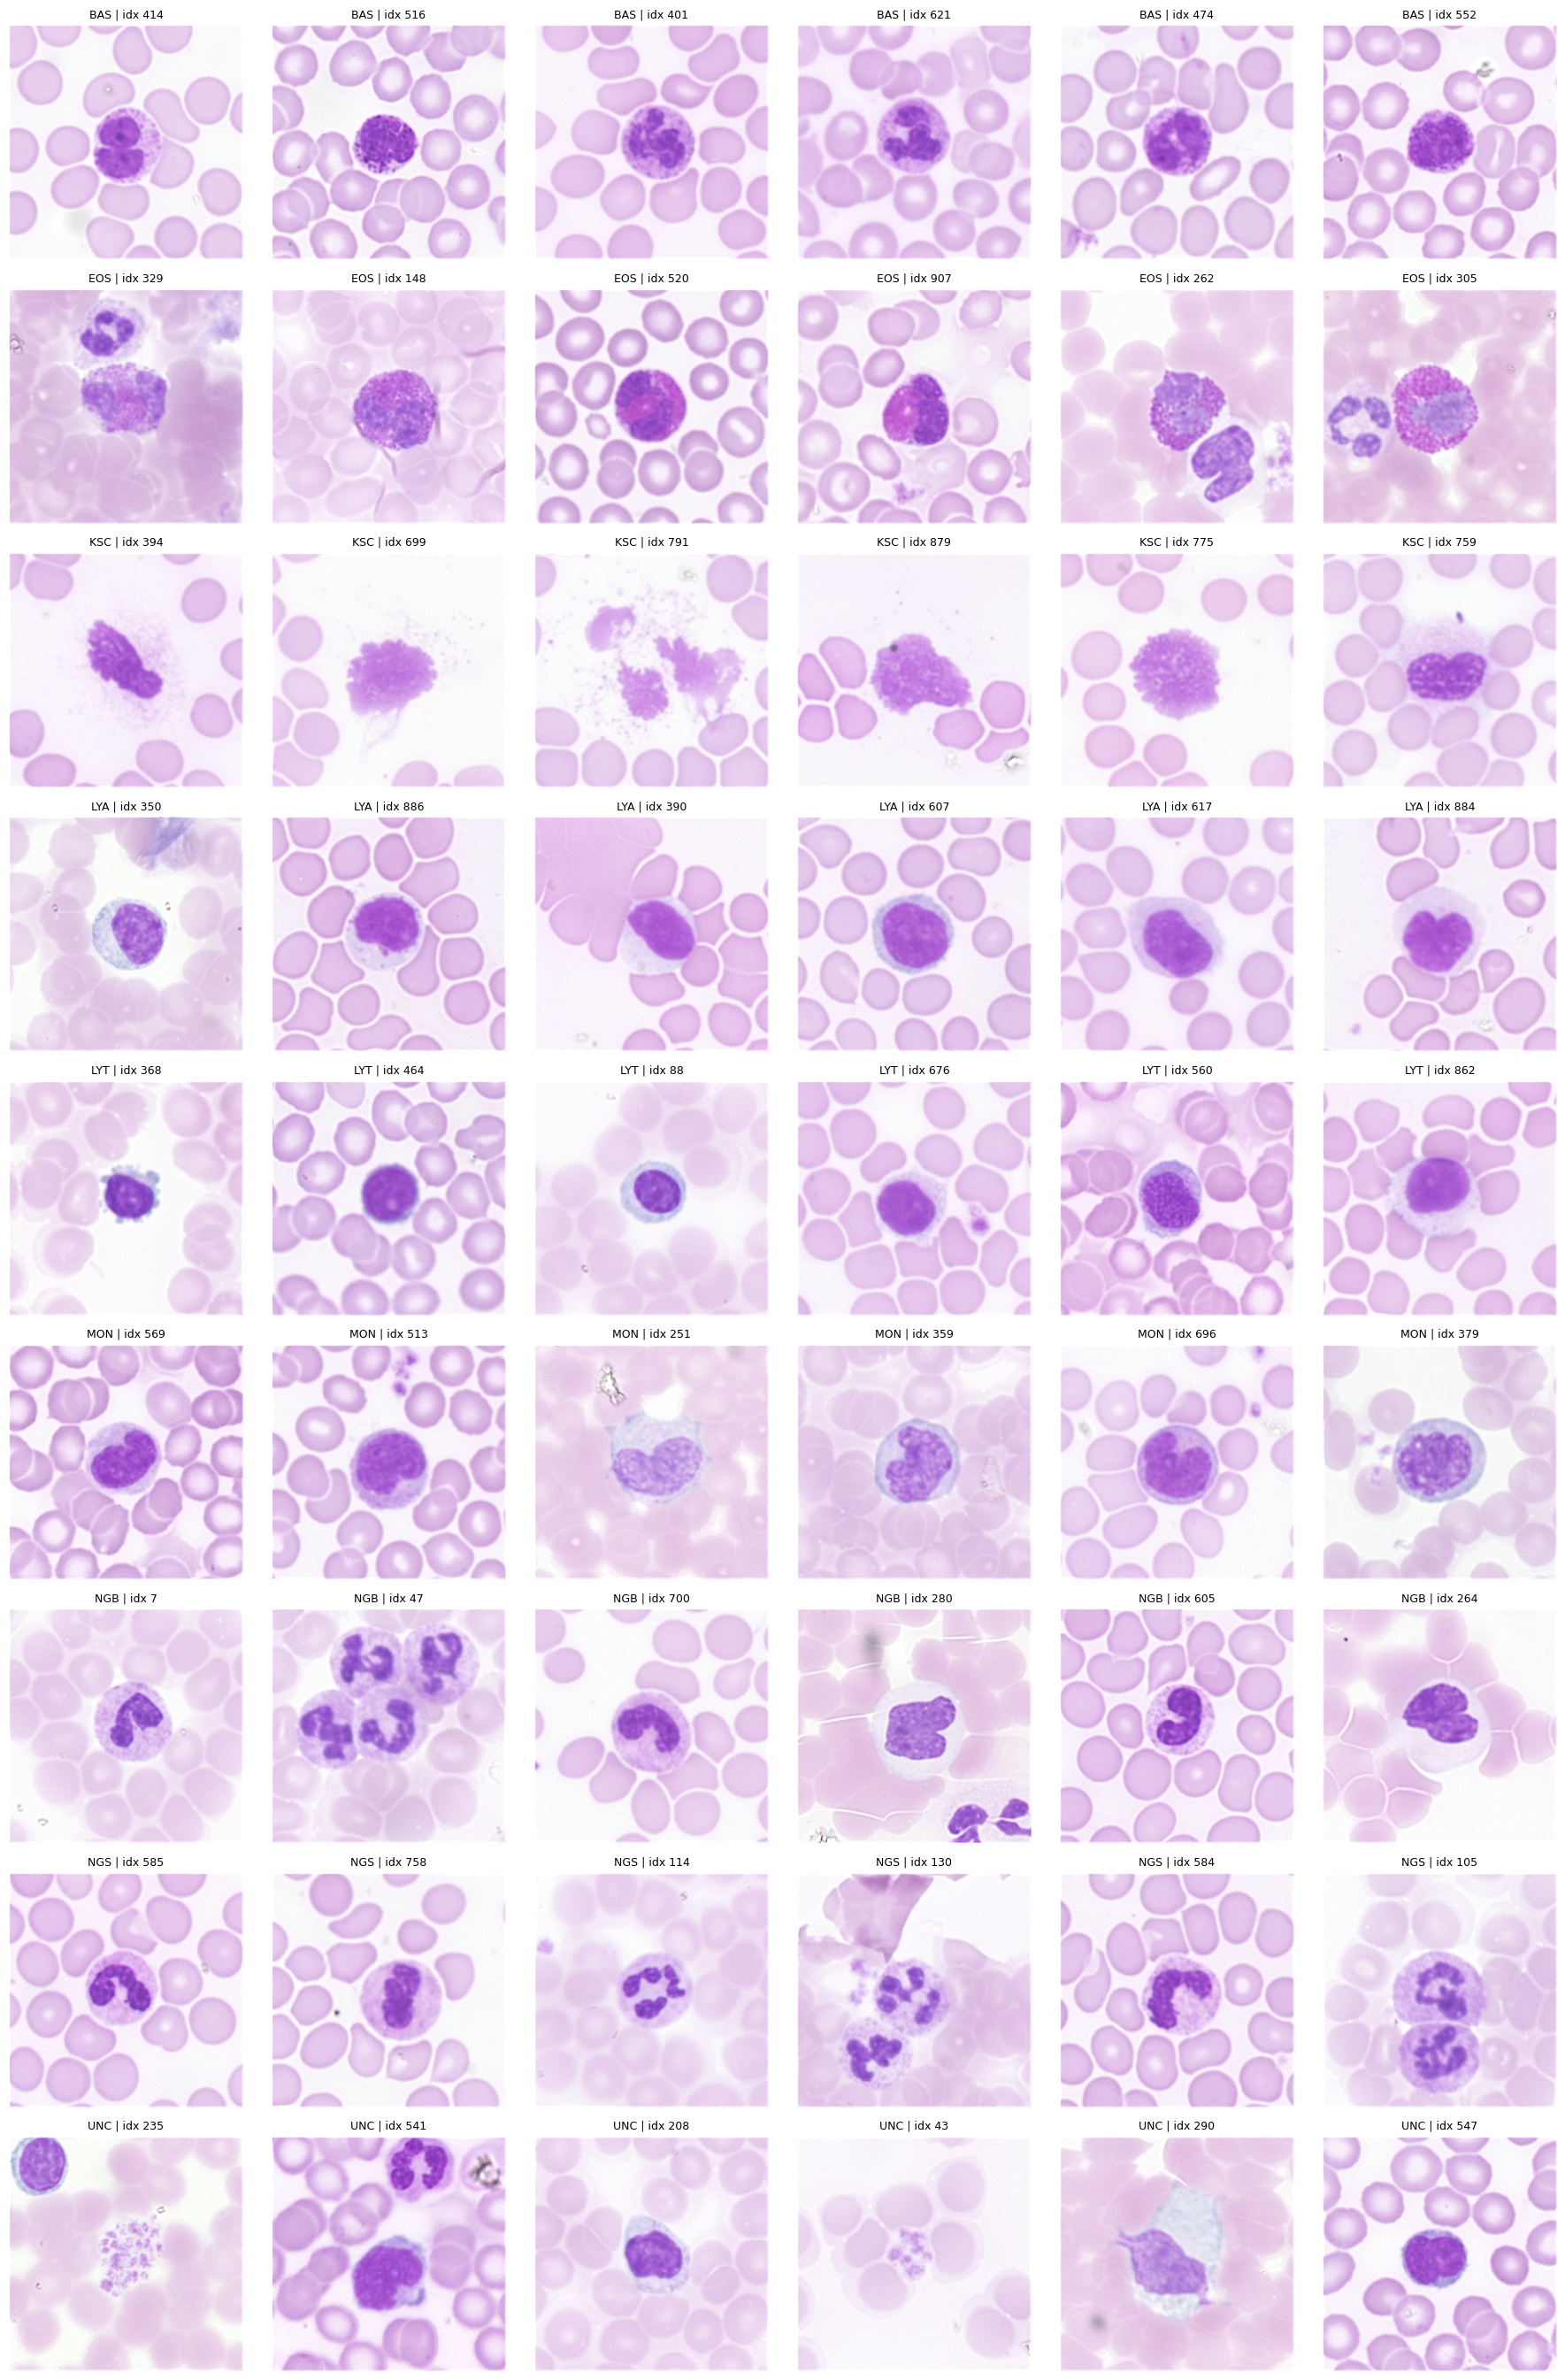

In [ ]:
rows = len(display_class_indices)
cols = int(cfg["samples_per_class"])
fig, axes = plt.subplots(rows, cols, figsize=(3.0 * cols, 3.0 * rows), squeeze=False)

for r, class_idx in enumerate(display_class_indices):
    class_name = dataset.classes[class_idx]
    pool = indices_by_class[class_idx]

    n_take = min(cols, len(pool))
    chosen = random.sample(pool, n_take)

    for c in range(cols):
        ax = axes[r][c]
        ax.axis("off")

        if c < n_take:
            sample_idx = chosen[c]
            img, _ = dataset[sample_idx]
            disp, cmap = to_display_image(img)
            if cmap is None:
                ax.imshow(disp)
            else:
                ax.imshow(disp, cmap=cmap)
            ax.set_title(f"{class_name} | idx {sample_idx}", fontsize=9)
        else:
            ax.text(0.5, 0.5, "N/A", ha="center", va="center")

    axes[r][0].set_ylabel(
        f"{class_name}\\n(n={len(pool)})",
        rotation=0,
        labelpad=40,
        fontsize=10,
        va="center",
    )

plt.tight_layout()
plt.show()


### Quick notes
- With `dataset="Microscopy"` and `visual_mode="train_static_like"`, images are shown after the static RAW pipeline used in training.
- With `visual_mode="as_loaded"`, the original normalized RAW image is shown (grayscale).
- To mirror your training setup, set the `cfg` parameters to match your training command.
